# 03 Hazard models

In this notebook, we fit all of the hazard models from the plan (`01-plan.md`) and compare them:

| Model | What changes | Why |
|---|---|---|
| Logit hazard | Nothing, this is the main model | The standard baseline, and widely used in credit scoring (Shumway, 2001) |
| Cloglog hazard | The link | The discrete version of the Cox model (Prentice & Gloeckler, 1978), so $e^{\beta}$ are hazard ratios |
| Logit hazard, L1 / L2 | A penalty, chosen by cross-validation | Tests whether shrinking the correlated coefficients helps |
| Cox, time-varying covariates | Continuous time | The most cited model in the literature (Cox, 1972), fitted on the same rows |

We also fit a logistic regression on the October rows only (one row per customer). This is the fair test of whether
using the extra months helps at all.

Everything is chosen on the training customers using 10-fold cross-validation, leaving out whole customers, as a
customer's rows are linked. The validation set is then used as a single check, and the test set is only used once
at the end.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from lifelines import CoxTimeVaryingFitter
from scipy.stats import bootstrap
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, log_loss, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GroupKFold

import prep

wide = prep.load_split()                  # train and validation; see 02-data.ipynb
pm = prep.person_months(wide)
train, val = pm["train"], pm["validation"]
{part: df.shape for part, df in pm.items()}

{'train': (89985, 21), 'validation': (29995, 21)}

## 1. The models

Every model predicts the monthly hazard $h(t \mid x)$ from last month's covariates $x_{t-1}$:

$$\text{link}\big(h(t \mid x)\big) = \alpha_t + \beta^\top x_{t-1}$$

* Logit - the link is $\log\frac{h}{1-h}$. This is a logistic regression on the person-month rows, fitted by maximum
  likelihood, and the coefficients $\beta$ are log odds ratios of the monthly hazard.
* Cloglog - the link is $\log(-\log(1-h))$. If defaults really happen in continuous time but we only see them
  monthly, this is the exact model, and $e^{\beta}$ are hazard ratios.
* Penalised - the logit model, but minimising the log loss plus $\frac1C$ times an L1 ($\sum|\beta_j|$) or L2
  ($\sum\beta_j^2$) penalty.
* Cox - $h(t \mid x) = h_0(t)\,e^{\beta^\top x_{t-1}}$, fitted by partial likelihood. Here the baseline $h_0$ takes
  the place of the month columns.

$\alpha_t$ is a separate intercept for each month, so the baseline hazard can take any shape. The reason this can be
fitted as an ordinary logistic regression is that the probability of a customer's history is the product, over
their months, of $h$ (event) or $1-h$ (no event), which is exactly a Bernoulli likelihood over the rows
(Allison, 1982).

In [2]:
LINKS = {"logit": sm.families.links.Logit(), "cloglog": sm.families.links.CLogLog()}


def fit_glm(data, link="logit", cols=None):
    """Discrete-time hazard: a binomial GLM on the person-month rows.

    Standard errors are clustered by customer (rows of one customer are not
    independent); the coefficients are the same either way.
    """
    cols = cols or prep.features(data)
    model = sm.GLM(data["event"], sm.add_constant(data[cols]), family=sm.families.Binomial(link=LINKS[link]))
    return model.fit(cov_type="cluster", cov_kwds={"groups": data.index.to_numpy()})


def fit_penalised(data, penalty="l2", C=1.0):
    """The logit hazard with a lasso (l1) or ridge (l2) penalty. Small C = strong penalty."""
    model = LogisticRegression(C=C, l1_ratio=1.0 if penalty == "l1" else 0.0,
                               solver="liblinear" if penalty == "l1" else "lbfgs", max_iter=2000)
    return model.fit(data[prep.features(data)], data["event"])


def fit_cox(data):
    """Cox model with time-varying covariates: each row is the interval (t-1, t].

    A small ridge penalty and a shorter Newton step stop it diverging (the default step
    gives coefficients near 45: the status dummies are nearly separable in some months).
    Ties, thousands of events per month, are handled by Efron's method.
    """
    cols = prep.features(data, months=False)
    df = data[cols].assign(id=data.index, start=data["t"] - 1, stop=data["t"],
                           event=data["event"].astype(bool)).reset_index(drop=True)
    model = CoxTimeVaryingFitter(penalizer=0.01)
    return model.fit(df, id_col="id", event_col="event", start_col="start", stop_col="stop",
                     fit_options={"step_size": 0.3}, show_progress=False)


def fit_october_only(data):
    """The ordinary one-row-per-customer logit: the October rows, no month dummies."""
    rows = prep.october(data)
    return fit_glm(rows, cols=prep.features(rows, months=False))


def predict(model, rows):
    """The hazard for each row. Cox has no predict for time-varying fits, so its monthly
    hazard is built from the baseline: h = 1 - exp(-[H0(t) - H0(t-1)] * exp((x - mean)'beta))."""
    if isinstance(model, CoxTimeVaryingFitter):
        H0 = model.baseline_cumulative_hazard_.iloc[:, 0]
        h0 = (H0.reindex(rows["t"]).to_numpy() - H0.reindex(rows["t"] - 1).fillna(0).to_numpy())
        p = 1 - np.exp(-h0 * model.predict_partial_hazard(rows[model.params_.index]).to_numpy())
    elif isinstance(model, LogisticRegression):
        p = model.predict_proba(rows[model.feature_names_in_])[:, 1]
    else:
        cols = [c for c in model.model.exog_names if c != "const"]
        p = model.predict(sm.add_constant(rows[cols], has_constant="add"))
    return pd.Series(np.asarray(p), index=rows.index, name="probability")


def predict_october(model, data):
    """P(default in October): the hazard of each customer's October row."""
    return predict(model, prep.october(data))


def score(y, p):
    """Ranking (AUC, average precision = area under the PR curve) and probabilities (Brier, log loss)."""
    return {"AUC": roc_auc_score(y, p), "avg precision": average_precision_score(y, p),
            "Brier": brier_score_loss(y, p), "log loss": log_loss(y, p)}


MODELS = {
    "logit hazard": lambda d: fit_glm(d, "logit"),
    "cloglog hazard": lambda d: fit_glm(d, "cloglog"),
    "logit hazard, L1": lambda d: fit_penalised(d, "l1", C=1.0),
    "logit hazard, L2": lambda d: fit_penalised(d, "l2", C=1.0),
    "Cox, time-varying": fit_cox,
    "logit, October rows only": fit_october_only,
}

## 2. Cross-validation with whole customers left out

As the rows are linked, the unit we leave out is the customer, not the customer-month. `GroupKFold` puts all five of
a customer's rows in the same fold, so no customer is used for both fitting and scoring. Each fold is scored on the
October rows of the customers left out, as this is the number the group compares.

In [3]:
FOLDS = list(GroupKFold(n_splits=10, shuffle=True, random_state=prep.SEED).split(train, groups=train.index))


def cross_validate(fit, data=train, folds=FOLDS):
    """Fit on 9 folds of customers, score the 10th on October; one row of scores per fold."""
    rows = []
    for fit_idx, score_idx in folds:
        model = fit(data.iloc[fit_idx])
        held_out = data.iloc[score_idx]
        rows.append(score(prep.october(held_out)["event"], predict_october(model, held_out)))
    return pd.DataFrame(rows)


cv_results = {name: cross_validate(fit) for name, fit in MODELS.items()}
cv_table = pd.DataFrame({name: cv.mean() for name, cv in cv_results.items()}).T
cv_table["AUC sd"] = [cv["AUC"].std() for cv in cv_results.values()]
cv_table.round(4)

,AUC,avg precision,Brier,log loss,AUC sd
logit hazard,0.7330,0.5066,0.1424,0.4582,0.0125
cloglog hazard,0.7303,0.5063,0.1436,0.4652,0.0121
"logit hazard, L1",0.7330,0.5067,0.1423,0.4582,0.0125
"logit hazard, L2",0.7329,0.5064,0.1424,0.4582,0.0126
"Cox, time-varying",0.7309,0.5049,0.1450,0.4722,0.0124
"logit, October rows only",0.7469,0.5161,0.1394,0.4456,0.0105


## 3. Model selection: bigger models always fit better

When one model contains another, the bigger one will always have the higher likelihood on the training data, so the
training fit cannot be used to choose between them. AIC, BIC and cross-validation all account for the extra
parameters. Below are four nested logit hazard models, each adding to the one before.

* BIC needs a sample size $n$, and here it is not clear what this should be - 90,000 rows or 18,000 customers? As
  the rows are not independent, the number of customers is arguably the right one, so both are shown.
* AIC and BIC also assume the rows are independent, whereas cross-validation by customer does not.

In [4]:
f = prep.features(train)
NESTED = {
    "months only": [c for c in f if c.startswith("t_")],
    "+ last month's status": [c for c in f if c.startswith(("t_", "status_lag"))],
    "+ utilisation, payment ratio": [c for c in f if c.startswith(("t_", "status_lag", "util", "payratio"))],
    "+ limit, age, demographics (full)": f,
}
n_rows, n_customers = len(train), train.index.nunique()
rows = []
for name, cols in NESTED.items():
    res = fit_glm(train, cols=cols)
    k = len(res.params)
    cv = cross_validate(lambda d, cols=cols: fit_glm(d, cols=cols))
    rows.append({"model": name, "parameters": k, "log-likelihood (train)": res.llf,
                 "AIC": res.aic, "BIC (n = rows)": -2 * res.llf + k * np.log(n_rows),
                 "BIC (n = customers)": -2 * res.llf + k * np.log(n_customers),
                 "CV log loss": cv["log loss"].mean(), "CV AUC": cv["AUC"].mean()})
selection = pd.DataFrame(rows).set_index("model")
selection.round(4)

,parameters,log-likelihood (train),AIC,BIC (n = rows),BIC (n = customers),CV log loss,CV AUC
model,,,,,,,
months only,5,-36962.4482,73934.8965,73981.9335,73973.8863,0.5285,0.5000
+ last month's status,10,-26443.9032,52907.8064,53001.8804,52985.7860,0.4667,0.6805
"+ utilisation, payment ratio",12,-26107.4455,52238.8910,52351.7798,52332.4666,0.4652,0.7034
"+ limit, age, demographics (full)",20,-25783.8990,51607.7981,51795.9460,51763.7573,0.4582,0.7330


## 4. Choosing the penalty by cross-validation

The penalty strength $C$ is chosen by cross-validation rather than on one held-out set, which would give a noisier
choice. We choose on log loss, as it rewards honest probabilities (Gneiting & Raftery, 2007), and show the AUC
alongside it.

In [5]:
GRID = np.logspace(-3, 1, 5)
rows = []
for pen in ("l1", "l2"):
    for C in GRID:
        cv = cross_validate(lambda d, pen=pen, C=C: fit_penalised(d, pen, C))
        rows.append({"penalty": pen, "C": C, "AUC mean": cv["AUC"].mean(), "AUC sd": cv["AUC"].std(),
                     "log loss mean": cv["log loss"].mean()})
tuning = pd.DataFrame(rows)
best_C = {pen: tuning.loc[tuning.loc[tuning["penalty"] == pen, "log loss mean"].idxmin(), "C"] for pen in ("l1", "l2")}
print("C chosen by CV log loss:", best_C)
tuning.round(4)

C chosen by CV log loss: {'l1': np.float64(0.01), 'l2': np.float64(0.01)}


,penalty,C,AUC mean,AUC sd,log loss mean
0,l1,0.001,0.7209,0.0136,0.4697
1,l1,0.010,0.7298,0.0134,0.4560
2,l1,0.100,0.7330,0.0126,0.4578
3,l1,1.000,0.7330,0.0125,0.4582
4,l1,10.000,0.7330,0.0125,0.4582
5,l2,0.001,0.7217,0.0147,0.4595
6,l2,0.010,0.7324,0.0129,0.4553
7,l2,0.100,0.7332,0.0125,0.4576
8,l2,1.000,0.7329,0.0126,0.4582
9,l2,10.000,0.7328,0.0126,0.4583


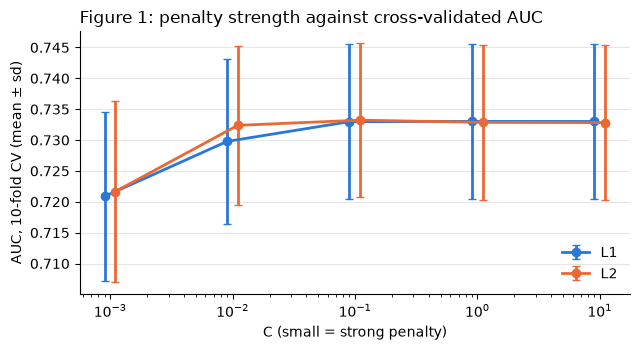

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for pen, colour, nudge in (("l1", "#2a78d6", 0.9), ("l2", "#eb6834", 1.1)):   # nudge: so the error bars don't overlap
    sub = tuning[tuning["penalty"] == pen]
    ax.errorbar(sub["C"] * nudge, sub["AUC mean"], yerr=sub["AUC sd"], marker="o", markersize=6, linewidth=2,
                capsize=3, color=colour, label=pen.upper())
ax.set_xscale("log")
ax.set_xlabel("C (small = strong penalty)")
ax.set_ylabel("AUC, 10-fold CV (mean ± sd)")
ax.set_title("Figure 1: penalty strength against cross-validated AUC", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 5. The check on the validation customers

Each model is fitted once on all of the training customers (the penalised models use the C chosen above) and scored
on the October row of the validation customers. Nothing has been chosen using these customers.

In [7]:
MODELS["logit hazard, L1"] = lambda d: fit_penalised(d, "l1", C=best_C["l1"])
MODELS["logit hazard, L2"] = lambda d: fit_penalised(d, "l2", C=best_C["l2"])
fitted = {name: fit(train) for name, fit in MODELS.items()}
y_val = prep.october(val)["event"]
p_val = {name: predict_october(m, val) for name, m in fitted.items()}
pd.DataFrame({name: score(y_val, p) for name, p in p_val.items()}).T.round(4)

,AUC,avg precision,Brier,log loss
logit hazard,0.7438,0.5297,0.1380,0.4460
cloglog hazard,0.7442,0.5323,0.1385,0.4502
"logit hazard, L1",0.7368,0.5212,0.1382,0.4460
"logit hazard, L2",0.7394,0.5236,0.1380,0.4457
"Cox, time-varying",0.7447,0.5307,0.1407,0.4597
"logit, October rows only",0.7503,0.5360,0.1365,0.4389


The ROC and precision-recall curves. The hazard models lie almost on top of each other, so only three are drawn:
the logit hazard, Cox and the October-only logistic regression.

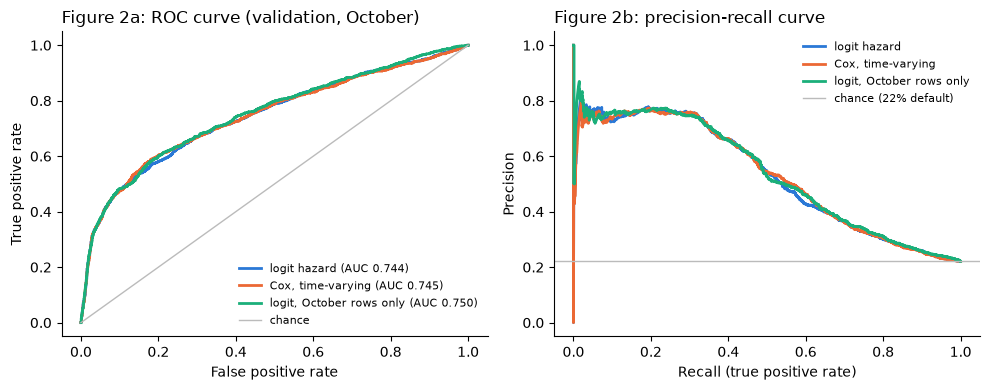

In [8]:
SHOW = {"logit hazard": "#2a78d6", "Cox, time-varying": "#eb6834", "logit, October rows only": "#1baf7a"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
for name, colour in SHOW.items():
    fpr, tpr, _ = roc_curve(y_val, p_val[name])
    precision, recall, _ = precision_recall_curve(y_val, p_val[name])
    ax1.plot(fpr, tpr, linewidth=2, color=colour, label=f"{name} (AUC {roc_auc_score(y_val, p_val[name]):.3f})")
    ax2.plot(recall, precision, linewidth=2, color=colour, label=name)
ax1.plot([0, 1], [0, 1], color="#bbbbbb", linewidth=1, label="chance")
ax2.axhline(y_val.mean(), color="#bbbbbb", linewidth=1, label=f"chance ({y_val.mean():.0%} default)")
ax1.set(xlabel="False positive rate", ylabel="True positive rate")
ax2.set(xlabel="Recall (true positive rate)", ylabel="Precision")
ax1.set_title("Figure 2a: ROC curve (validation, October)", loc="left")
ax2.set_title("Figure 2b: precision-recall curve", loc="left")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

Is the difference between the October-only model and the logit hazard real? To check, we use a paired bootstrap over
the validation customers, resampling customers and keeping each customer's label and both predictions together.

In [9]:
def auc_difference(y, p_a, p_b):
    return roc_auc_score(y, p_a) - roc_auc_score(y, p_b)


a, b = "logit, October rows only", "logit hazard"
boot = bootstrap((y_val.to_numpy(), p_val[a].to_numpy(), p_val[b].to_numpy()), auc_difference, paired=True,
                 vectorized=False, n_resamples=1000, method="percentile", random_state=prep.SEED)
print(f"AUC({a}) - AUC({b}) = {auc_difference(y_val, p_val[a], p_val[b]):.4f}, "
      f"95% interval [{boot.confidence_interval.low:.4f}, {boot.confidence_interval.high:.4f}]")

AUC(logit, October rows only) - AUC(logit hazard) = 0.0065, 95% interval [-0.0021, 0.0147]


## 6. Logit against cloglog, and the clustered standard errors

When the monthly hazards are small, we expect the two links to give almost the same coefficients. The last column
shows how much bigger the standard errors are when clustered by customer, compared with the standard errors that
assume the rows are independent.

In [10]:
logit, cloglog = fitted["logit hazard"], fitted["cloglog hazard"]
naive = sm.GLM(logit.model.endog, logit.model.exog, family=logit.model.family).fit()
pd.DataFrame({"logit": logit.params, "cloglog": cloglog.params, "cloglog hazard ratio": np.exp(cloglog.params),
              "clustered / naive SE": logit.bse / naive.bse}).round(3)

,logit,cloglog,cloglog hazard ratio,clustered / naive SE
const,-2.268,-2.270,0.103,0.955
util_lag,0.065,0.034,1.035,0.997
payratio_lag,-0.315,-0.283,0.753,1.032
log_limit,-0.294,-0.200,0.819,0.945
age,0.038,0.024,1.025,0.943
status_lag_-2,-0.671,-0.707,0.493,0.971
status_lag_0,-0.542,-0.432,0.649,1.033
status_lag_1,0.788,0.907,2.477,1.044
status_lag_2,2.656,2.125,8.370,1.042
status_lag_3,3.061,2.292,9.894,1.030


## 7. Calibration

A good Brier score or log loss does not guarantee good calibration, so we check it directly on the validation
customers in two ways. By month, we compare the average predicted hazard with the actual event rate, following the
actual-vs-expected idea from Botha & Muller (2025). In October, we use `calibration_curve` with ten equal-sized bins,
to see whether a predicted 30% really means 30% default.

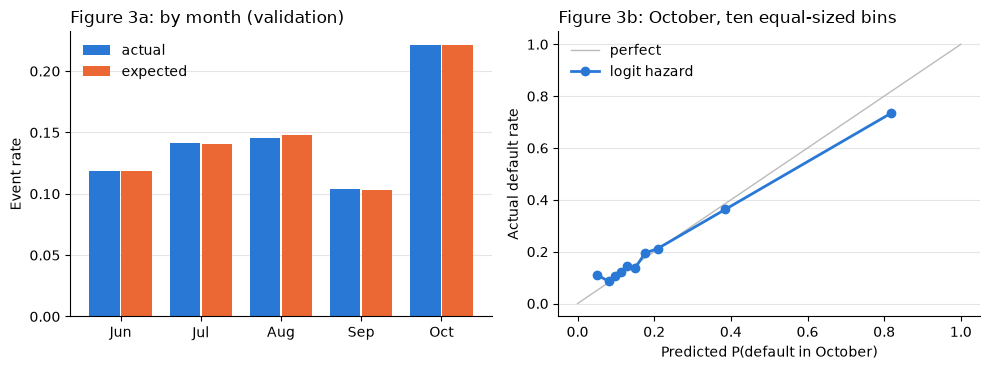

,predicted,actual
0,0.050,0.112
1,0.082,0.085
2,0.098,0.107
3,0.113,0.122
4,0.130,0.143
5,0.151,0.139
6,0.176,0.195
7,0.209,0.212
8,0.386,0.363
9,0.819,0.735


In [11]:
p_all = predict(logit, val)
term = pd.DataFrame({"actual": val.groupby("t")["event"].mean(), "expected": p_all.groupby(val["t"]).mean()})
actual_rate, predicted_rate = calibration_curve(y_val, p_val["logit hazard"], n_bins=10, strategy="quantile")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
x = np.arange(len(term))
ax1.bar(x - 0.2, term["actual"], width=0.38, color="#2a78d6", label="actual")
ax1.bar(x + 0.2, term["expected"], width=0.38, color="#eb6834", label="expected")
ax1.set_xticks(x, ["Jun", "Jul", "Aug", "Sep", "Oct"])
ax1.set_ylabel("Event rate")
ax1.set_title("Figure 3a: by month (validation)", loc="left")
ax1.legend(frameon=False)
ax2.plot([0, 1], [0, 1], color="#bbbbbb", linewidth=1, label="perfect")
ax2.plot(predicted_rate, actual_rate, marker="o", markersize=6, linewidth=2, color="#2a78d6", label="logit hazard")
ax2.set_xlabel("Predicted P(default in October)")
ax2.set_ylabel("Actual default rate")
ax2.set_title("Figure 3b: October, ten equal-sized bins", loc="left")
ax2.legend(frameon=False)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5")
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()
pd.DataFrame({"predicted": predicted_rate, "actual": actual_rate}).round(3)

## 8. The next month

Here, we fit on the training customers' months up to August and then predict September for the validation
customers, so the model has never seen September. We compare this with a model that has seen September (fitted up
to September). Both use the proxy event and both leave out the month columns, as the model fitted up to August has
no September column to estimate. We only compare AUC - within a single month, a missing intercept shifts every
prediction by the same amount, which changes the Brier score and log loss but not the ranking.

In [12]:
SEPTEMBER = prep.OCTOBER - 1
no_months = prep.features(train, months=False)
val_sep = val[val["t"] == SEPTEMBER]
forward = {}
for label, last_month in (("fitted up to August (forward in time)", SEPTEMBER - 1),
                          ("fitted up to September (seen the month)", SEPTEMBER)):
    model = fit_glm(train[train["t"] <= last_month], cols=no_months)
    forward[label] = roc_auc_score(val_sep["event"], predict(model, val_sep))
pd.Series(forward, name="AUC, validation customers, September").round(4)

fitted up to August (forward in time)      0.8568
fitted up to September (seen the month)    0.8584
Name: AUC, validation customers, September, dtype: float64

## 9. Test-set predictions (run once, when the model is final)

This writes `data/output/predictions-alex.csv` (customer ID and probability), which the group's metric notebook
scores. It is commented out so the test set is not used while the models are still changing.

In [13]:
# pm_test = prep.person_months(prep.load_split(("train", "test")))     # standardised with the training rows
# predict_october(fitted["logit hazard"], pm_test["test"]).to_csv(prep.ROOT / "data" / "output" / "predictions-alex.csv")

## 10. What this shows

These results come from the run saved in this notebook, which is seeded so it gives the same numbers each time.

* The hazard models barely differ from each other (section 2), with cross-validated AUC between 0.731 and 0.733.
  So the link, the penalty and continuous against discrete time are not what limits the model. The logit and
  cloglog coefficients agree, as expected when the monthly hazards are small (section 6).
* Using the extra months does not help. The October-only model does better in cross-validation (AUC 0.747 against
  0.733, with a fold standard deviation of about 0.01, and log loss 0.446 against 0.458). On the validation
  customers the gap is smaller (0.0065) and its bootstrap interval includes 0 (section 5). The earlier months use
  the proxy event, so the coefficients shared across the months mix two questions - for predicting October, the
  October rows on their own do as well or better. This is a result about the data rather than a problem with the
  code, and it is the main finding to report.
* The bigger models are better by every measure (section 3). AIC, BIC with either $n$, and cross-validation all pick
  the full model, and the training likelihood goes up at every step, as it has to for nested models. With 18,000
  customers, the BIC penalty is small compared with the gains in likelihood, so whether $n$ is rows or customers does
  not change the choice.
* The penalty makes very little difference (section 4). Cross-validation picks C = 0.01 for both L1 and L2 on log
  loss, a gain of 0.003, and the AUC is flat from C = 0.1 upwards.
* Calibration (section 7) - the monthly event rates are matched almost exactly, but in October the model is too
  confident at the extremes. The lowest tenth is predicted at 5% when 11% actually default, and the top tenth is
  predicted at 82% when 74% default.
* The next month (section 8) - predicting September from a model only fitted up to August costs almost nothing (AUC
  0.857 against 0.858), so over one month the relationships are stable.
* The clustered standard errors are within about 12% of the ones that assume independent rows (section 6). Last
  month's status, which is a covariate, already carries most of the link between a customer's rows.

Next, `04-clustering.ipynb`.